# Лабораторна робота № 2

## Оптимізаційна задача та аналіз чутливості

**Дисципліна:** Інтелектуальний аналіз та візуалізація даних (СК26)
**Тривалість:** 2 год аудиторно + 3 год самостійної роботи · **Максимальна оцінка:** 4 бали

---

### Мета роботи

Побудувати оптимізаційну модель у двох середовищах, прочитати звіт про стійкість
і **ухвалити на його основі господарське рішення**.

Розв'язати задачу — не мета. Solver зробить це за дві секунди. Робота оцінюється за
те, що ви зумієте зі звіту витягнути.

### Дві частини

| Частина | Задача | Де виконується |
|---|---|---|
| **1** | виробнича задача — Excel і Python | аудиторно |
| **2** | транспортна задача — Python | самостійно |

Друга частина потрібна не для повторення. Там та сама методика поводиться інакше,
і ви маєте побачити, де саме проходить межа її застосовності.

### Що здається

1. Цей файл `.ipynb` із заповненими розв'язками. **Виконується згори донизу на чистому
   ядрі** (Kernel → Restart & Run All) без помилок — перевіряється першою дією на захисті.
2. Файл Excel з моделлю, налаштуваннями Solver і **звітом про стійкість** окремим аркушем.
3. Заповнена декларація про використання ШІ (етап 12).

### Оцінювання

| Бали | Що досягнуто |
|---|---|
| 0 | Модель не сформульовано або розв'язок не отримано |
| 1 | Розв'язок отримано лише в одному середовищі, звіт про стійкість не проаналізовано |
| 2 | Задачу розв'язано в обох середовищах і звіти зіставлено, але тіньові ціни та діапазони не інтерпретовано |
| 4 | Звіт прочитано й перевірено експериментом, ухвалено обґрунтоване рішення про закупівлю, виконано частину 2 з поясненням розбіжності |

---
## Крок 0. Ваші дані та варіант

In [1]:
ПІБ = 'Яцишин Роман'        # напр. 'Шевченко Тарас'
ГРУПА = 'ШІ-32'      # напр. 'КН-31'
ВАРІАНТ = 19     # ваш номер за списком групи

assert ПІБ and ГРУПА and 1 <= ВАРІАНТ <= 30, 'Заповніть ПІБ, ГРУПУ та ВАРІАНТ (1..30)'


In [2]:
# --- клітинку не редагувати: вона видає дані вашого варіанта -----------------
import json, numpy as np, pandas as pd

ДАНІ_ВАРІАНТІВ = json.loads('''{"1": {"фірма": "«Астро-ТВ»", "що": "телевізори", "од": "шт./день", "вироби": ["Astro", "Cosmo", "Nova", "Vega"], "ресурси": ["Конвеєр A, год", "Конвеєр Б, год", "Цех кінескопів, год", "Цех корпусів, год", "Ділянка збирання, год"], "A": [[0, 2, 1, 1], [3, 3, 0, 6], [2, 3, 0, 2], [4, 6, 0, 5], [3, 1, 5, 4]], "c": [21, 69, 44, 39], "b": [929, 410, 507, 865, 425], "ресурс_пропозиції": 1, "ціна_пропозиції": 16.2, "обсяг_пропозиції": 44}, "2": {"фірма": "«Longer Boats»", "що": "яхти", "од": "шт./місяць", "вироби": ["Sting", "Ray", "Breaker", "Marlin"], "ресурси": ["Склопластик, м²", "Столярний цех, год", "Фарбувальний цех, год", "Такелаж, компл.", "Ділянка добудови, год"], "A": [[4, 2, 5, 2], [6, 5, 4, 2], [5, 2, 0, 3], [2, 1, 5, 0], [5, 5, 6, 2]], "c": [40, 66, 24, 34], "b": [1271, 702, 915, 1388, 804], "ресурс_пропозиції": 1, "ціна_пропозиції": 16.7, "обсяг_пропозиції": 204}, "3": {"фірма": "«Карпатський дуб»", "що": "меблі", "од": "шт./тиждень", "вироби": ["Крісло", "Стілець", "Табурет", "Лава"], "ресурси": ["Дубовий брус, м", "Фанера, м²", "Фурнітура, компл.", "Верстат, год", "Лакування, год"], "A": [[5, 2, 6, 6], [3, 4, 3, 6], [1, 6, 6, 0], [3, 1, 6, 1], [4, 1, 1, 4]], "c": [51, 16, 34, 22], "b": [1189, 686, 1311, 512, 1030], "ресурс_пропозиції": 3, "ціна_пропозиції": 11.3, "обсяг_пропозиції": 348}, "4": {"фірма": "«Друк-Сервіс»", "що": "поліграфію", "од": "тис. прим./тиждень", "вироби": ["Буклет", "Каталог", "Календар", "Плакат"], "ресурси": ["Крейдований папір, кг", "Офсетний папір, кг", "Фарба, кг", "Друкарська машина, год", "Різка й фальцювання, год"], "A": [[5, 0, 0, 0], [1, 0, 5, 2], [2, 4, 6, 5], [3, 0, 5, 3], [2, 1, 2, 5]], "c": [41, 50, 54, 26], "b": [815, 344, 840, 840, 382], "ресурс_пропозиції": 4, "ціна_пропозиції": 8.3, "обсяг_пропозиції": 144}, "5": {"фірма": "«Астро-ТВ»", "що": "телевізори", "од": "шт./день", "вироби": ["Astro", "Cosmo", "Nova", "Vega"], "ресурси": ["Конвеєр A, год", "Конвеєр Б, год", "Цех кінескопів, год", "Цех корпусів, год", "Ділянка збирання, год"], "A": [[3, 0, 6, 6], [3, 2, 2, 4], [5, 5, 0, 6], [2, 1, 5, 3], [5, 5, 4, 2]], "c": [32, 66, 25, 24], "b": [874, 1034, 1349, 845, 1394], "ресурс_пропозиції": 2, "ціна_пропозиції": 8.6, "обсяг_пропозиції": 90}, "6": {"фірма": "«Longer Boats»", "що": "яхти", "од": "шт./місяць", "вироби": ["Sting", "Ray", "Breaker", "Marlin"], "ресурси": ["Склопластик, м²", "Столярний цех, год", "Фарбувальний цех, год", "Такелаж, компл.", "Ділянка добудови, год"], "A": [[3, 2, 1, 4], [4, 2, 2, 1], [3, 5, 1, 2], [3, 2, 0, 2], [6, 4, 6, 3]], "c": [40, 62, 19, 57], "b": [630, 391, 1349, 811, 1085], "ресурс_пропозиції": 1, "ціна_пропозиції": 29.5, "обсяг_пропозиції": 268}, "7": {"фірма": "«Карпатський дуб»", "що": "меблі", "од": "шт./тиждень", "вироби": ["Крісло", "Стілець", "Табурет", "Лава"], "ресурси": ["Дубовий брус, м", "Фанера, м²", "Фурнітура, компл.", "Верстат, год", "Лакування, год"], "A": [[0, 0, 5, 5], [4, 4, 0, 1], [2, 4, 0, 6], [6, 3, 4, 1], [2, 2, 1, 0]], "c": [20, 59, 63, 41], "b": [1189, 1189, 1217, 915, 424], "ресурс_пропозиції": 3, "ціна_пропозиції": 8.0, "обсяг_пропозиції": 314}, "8": {"фірма": "«Друк-Сервіс»", "що": "поліграфію", "од": "тис. прим./тиждень", "вироби": ["Буклет", "Каталог", "Календар", "Плакат"], "ресурси": ["Крейдований папір, кг", "Офсетний папір, кг", "Фарба, кг", "Друкарська машина, год", "Різка й фальцювання, год"], "A": [[2, 1, 3, 5], [3, 1, 0, 6], [1, 6, 1, 5], [2, 2, 4, 0], [6, 1, 2, 2]], "c": [60, 25, 59, 25], "b": [1279, 761, 376, 1230, 1065], "ресурс_пропозиції": 3, "ціна_пропозиції": 9.5, "обсяг_пропозиції": 234}, "9": {"фірма": "«Астро-ТВ»", "що": "телевізори", "од": "шт./день", "вироби": ["Astro", "Cosmo", "Nova", "Vega"], "ресурси": ["Конвеєр A, год", "Конвеєр Б, год", "Цех кінескопів, год", "Цех корпусів, год", "Ділянка збирання, год"], "A": [[5, 2, 1, 2], [5, 0, 1, 3], [5, 4, 6, 4], [4, 1, 1, 5], [6, 0, 3, 0]], "c": [58, 39, 54, 16], "b": [1147, 1199, 1280, 404, 1170], "ресурс_пропозиції": 2, "ціна_пропозиції": 6.1, "обсяг_пропозиції": 672}, "10": {"фірма": "«Longer Boats»", "що": "яхти", "од": "шт./місяць", "вироби": ["Sting", "Ray", "Breaker", "Marlin"], "ресурси": ["Склопластик, м²", "Столярний цех, год", "Фарбувальний цех, год", "Такелаж, компл.", "Ділянка добудови, год"], "A": [[4, 0, 4, 3], [0, 6, 0, 6], [5, 5, 3, 5], [6, 2, 3, 3], [3, 0, 0, 4]], "c": [20, 29, 37, 63], "b": [905, 344, 866, 1390, 355], "ресурс_пропозиції": 0, "ціна_пропозиції": 5.3, "обсяг_пропозиції": 78}, "11": {"фірма": "«Карпатський дуб»", "що": "меблі", "од": "шт./тиждень", "вироби": ["Крісло", "Стілець", "Табурет", "Лава"], "ресурси": ["Дубовий брус, м", "Фанера, м²", "Фурнітура, компл.", "Верстат, год", "Лакування, год"], "A": [[2, 1, 0, 3], [3, 1, 4, 0], [1, 0, 3, 2], [3, 2, 2, 6], [3, 6, 0, 3]], "c": [30, 16, 51, 35], "b": [1312, 838, 1062, 1038, 1236], "ресурс_пропозиції": 1, "ціна_пропозиції": 15.6, "обсяг_пропозиції": 778}, "12": {"фірма": "«Друк-Сервіс»", "що": "поліграфію", "од": "тис. прим./тиждень", "вироби": ["Буклет", "Каталог", "Календар", "Плакат"], "ресурси": ["Крейдований папір, кг", "Офсетний папір, кг", "Фарба, кг", "Друкарська машина, год", "Різка й фальцювання, год"], "A": [[5, 2, 0, 5], [1, 1, 3, 6], [6, 3, 5, 4], [2, 4, 6, 0], [4, 6, 2, 4]], "c": [39, 55, 36, 26], "b": [788, 661, 458, 1005, 535], "ресурс_пропозиції": 4, "ціна_пропозиції": 5.0, "обсяг_пропозиції": 762}, "13": {"фірма": "«Астро-ТВ»", "що": "телевізори", "од": "шт./день", "вироби": ["Astro", "Cosmo", "Nova", "Vega"], "ресурси": ["Конвеєр A, год", "Конвеєр Б, год", "Цех кінескопів, год", "Цех корпусів, год", "Ділянка збирання, год"], "A": [[1, 5, 3, 0], [6, 4, 6, 3], [4, 4, 4, 1], [0, 3, 5, 3], [3, 5, 3, 3]], "c": [59, 42, 53, 19], "b": [937, 1390, 603, 1120, 1334], "ресурс_пропозиції": 2, "ціна_пропозиції": 15.1, "обсяг_пропозиції": 646}, "14": {"фірма": "«Longer Boats»", "що": "яхти", "од": "шт./місяць", "вироби": ["Sting", "Ray", "Breaker", "Marlin"], "ресурси": ["Склопластик, м²", "Столярний цех, год", "Фарбувальний цех, год", "Такелаж, компл.", "Ділянка добудови, год"], "A": [[4, 3, 3, 4], [6, 6, 1, 6], [1, 3, 5, 1], [1, 5, 1, 4], [4, 4, 0, 3]], "c": [26, 56, 41, 40], "b": [969, 672, 1364, 878, 618], "ресурс_пропозиції": 2, "ціна_пропозиції": 5.0, "обсяг_пропозиції": 222}, "15": {"фірма": "«Карпатський дуб»", "що": "меблі", "од": "шт./тиждень", "вироби": ["Крісло", "Стілець", "Табурет", "Лава"], "ресурси": ["Дубовий брус, м", "Фанера, м²", "Фурнітура, компл.", "Верстат, год", "Лакування, год"], "A": [[5, 3, 3, 1], [2, 5, 6, 6], [3, 1, 0, 0], [0, 4, 4, 6], [2, 2, 2, 6]], "c": [64, 58, 34, 63], "b": [613, 316, 1035, 739, 810], "ресурс_пропозиції": 0, "ціна_пропозиції": 5.4, "обсяг_пропозиції": 354}, "16": {"фірма": "«Друк-Сервіс»", "що": "поліграфію", "од": "тис. прим./тиждень", "вироби": ["Буклет", "Каталог", "Календар", "Плакат"], "ресурси": ["Крейдований папір, кг", "Офсетний папір, кг", "Фарба, кг", "Друкарська машина, год", "Різка й фальцювання, год"], "A": [[1, 6, 4, 2], [4, 1, 1, 2], [4, 4, 6, 6], [5, 6, 3, 3], [1, 2, 4, 2]], "c": [33, 40, 58, 17], "b": [412, 1005, 996, 599, 390], "ресурс_пропозиції": 4, "ціна_пропозиції": 8.2, "обсяг_пропозиції": 44}, "17": {"фірма": "«Астро-ТВ»", "що": "телевізори", "од": "шт./день", "вироби": ["Astro", "Cosmo", "Nova", "Vega"], "ресурси": ["Конвеєр A, год", "Конвеєр Б, год", "Цех кінескопів, год", "Цех корпусів, год", "Ділянка збирання, год"], "A": [[2, 6, 0, 3], [2, 5, 5, 3], [6, 0, 4, 5], [1, 3, 6, 2], [0, 1, 4, 4]], "c": [33, 52, 20, 66], "b": [989, 1079, 873, 1327, 1224], "ресурс_пропозиції": 0, "ціна_пропозиції": 5.9, "обсяг_пропозиції": 402}, "18": {"фірма": "«Longer Boats»", "що": "яхти", "од": "шт./місяць", "вироби": ["Sting", "Ray", "Breaker", "Marlin"], "ресурси": ["Склопластик, м²", "Столярний цех, год", "Фарбувальний цех, год", "Такелаж, компл.", "Ділянка добудови, год"], "A": [[2, 3, 0, 1], [0, 6, 1, 6], [1, 0, 4, 1], [2, 6, 3, 4], [3, 1, 6, 5]], "c": [66, 54, 18, 66], "b": [1217, 668, 923, 1040, 619], "ресурс_пропозиції": 4, "ціна_пропозиції": 34.9, "обсяг_пропозиції": 100}, "19": {"фірма": "«Карпатський дуб»", "що": "меблі", "од": "шт./тиждень", "вироби": ["Крісло", "Стілець", "Табурет", "Лава"], "ресурси": ["Дубовий брус, м", "Фанера, м²", "Фурнітура, компл.", "Верстат, год", "Лакування, год"], "A": [[2, 1, 0, 2], [3, 3, 4, 5], [2, 1, 0, 4], [4, 1, 5, 0], [0, 3, 6, 3]], "c": [67, 52, 41, 40], "b": [315, 617, 815, 423, 1193], "ресурс_пропозиції": 1, "ціна_пропозиції": 9.3, "обсяг_пропозиції": 332}, "20": {"фірма": "«Друк-Сервіс»", "що": "поліграфію", "од": "тис. прим./тиждень", "вироби": ["Буклет", "Каталог", "Календар", "Плакат"], "ресурси": ["Крейдований папір, кг", "Офсетний папір, кг", "Фарба, кг", "Друкарська машина, год", "Різка й фальцювання, год"], "A": [[5, 4, 5, 1], [2, 0, 5, 4], [4, 0, 2, 3], [3, 3, 4, 3], [4, 4, 5, 2]], "c": [42, 63, 35, 56], "b": [1191, 331, 685, 1275, 971], "ресурс_пропозиції": 4, "ціна_пропозиції": 12.2, "обсяг_пропозиції": 604}, "21": {"фірма": "«Астро-ТВ»", "що": "телевізори", "од": "шт./день", "вироби": ["Astro", "Cosmo", "Nova", "Vega"], "ресурси": ["Конвеєр A, год", "Конвеєр Б, год", "Цех кінескопів, год", "Цех корпусів, год", "Ділянка збирання, год"], "A": [[5, 5, 3, 6], [4, 4, 3, 2], [4, 4, 4, 0], [1, 1, 5, 3], [0, 2, 6, 5]], "c": [32, 66, 26, 64], "b": [464, 393, 354, 597, 887], "ресурс_пропозиції": 0, "ціна_пропозиції": 9.4, "обсяг_пропозиції": 190}, "22": {"фірма": "«Longer Boats»", "що": "яхти", "од": "шт./місяць", "вироби": ["Sting", "Ray", "Breaker", "Marlin"], "ресурси": ["Склопластик, м²", "Столярний цех, год", "Фарбувальний цех, год", "Такелаж, компл.", "Ділянка добудови, год"], "A": [[6, 0, 2, 6], [3, 4, 0, 4], [4, 3, 1, 5], [5, 5, 6, 2], [2, 0, 1, 5]], "c": [65, 36, 50, 63], "b": [891, 1247, 613, 1070, 1259], "ресурс_пропозиції": 2, "ціна_пропозиції": 13.6, "обсяг_пропозиції": 64}, "23": {"фірма": "«Карпатський дуб»", "що": "меблі", "од": "шт./тиждень", "вироби": ["Крісло", "Стілець", "Табурет", "Лава"], "ресурси": ["Дубовий брус, м", "Фанера, м²", "Фурнітура, компл.", "Верстат, год", "Лакування, год"], "A": [[1, 2, 4, 6], [4, 6, 2, 5], [0, 5, 3, 1], [0, 0, 5, 1], [5, 4, 0, 5]], "c": [15, 35, 49, 23], "b": [1251, 637, 304, 629, 923], "ресурс_пропозиції": 2, "ціна_пропозиції": 10.9, "обсяг_пропозиції": 146}, "24": {"фірма": "«Друк-Сервіс»", "що": "поліграфію", "од": "тис. прим./тиждень", "вироби": ["Буклет", "Каталог", "Календар", "Плакат"], "ресурси": ["Крейдований папір, кг", "Офсетний папір, кг", "Фарба, кг", "Друкарська машина, год", "Різка й фальцювання, год"], "A": [[3, 2, 6, 1], [0, 2, 5, 6], [2, 4, 4, 0], [5, 6, 2, 5], [2, 4, 2, 1]], "c": [45, 61, 59, 38], "b": [927, 1384, 1294, 798, 323], "ресурс_пропозиції": 4, "ціна_пропозиції": 20.5, "обсяг_пропозиції": 110}, "25": {"фірма": "«Астро-ТВ»", "що": "телевізори", "од": "шт./день", "вироби": ["Astro", "Cosmo", "Nova", "Vega"], "ресурси": ["Конвеєр A, год", "Конвеєр Б, год", "Цех кінескопів, год", "Цех корпусів, год", "Ділянка збирання, год"], "A": [[5, 5, 4, 4], [2, 1, 4, 1], [3, 1, 4, 4], [1, 4, 2, 0], [6, 4, 6, 6]], "c": [35, 27, 63, 61], "b": [1399, 843, 308, 1393, 713], "ресурс_пропозиції": 2, "ціна_пропозиції": 7.7, "обсяг_пропозиції": 334}, "26": {"фірма": "«Longer Boats»", "що": "яхти", "од": "шт./місяць", "вироби": ["Sting", "Ray", "Breaker", "Marlin"], "ресурси": ["Склопластик, м²", "Столярний цех, год", "Фарбувальний цех, год", "Такелаж, компл.", "Ділянка добудови, год"], "A": [[4, 1, 4, 4], [3, 1, 5, 0], [6, 3, 6, 3], [1, 3, 6, 1], [6, 4, 5, 2]], "c": [46, 57, 60, 39], "b": [513, 1330, 796, 406, 1258], "ресурс_пропозиції": 3, "ціна_пропозиції": 18.1, "обсяг_пропозиції": 448}, "27": {"фірма": "«Карпатський дуб»", "що": "меблі", "од": "шт./тиждень", "вироби": ["Крісло", "Стілець", "Табурет", "Лава"], "ресурси": ["Дубовий брус, м", "Фанера, м²", "Фурнітура, компл.", "Верстат, год", "Лакування, год"], "A": [[2, 1, 6, 0], [6, 5, 6, 0], [5, 2, 3, 0], [6, 4, 3, 6], [6, 0, 0, 3]], "c": [24, 61, 50, 57], "b": [1179, 1358, 417, 463, 610], "ресурс_пропозиції": 3, "ціна_пропозиції": 9.0, "обсяг_пропозиції": 742}, "28": {"фірма": "«Друк-Сервіс»", "що": "поліграфію", "од": "тис. прим./тиждень", "вироби": ["Буклет", "Каталог", "Календар", "Плакат"], "ресурси": ["Крейдований папір, кг", "Офсетний папір, кг", "Фарба, кг", "Друкарська машина, год", "Різка й фальцювання, год"], "A": [[4, 5, 6, 2], [6, 4, 2, 1], [0, 5, 4, 3], [6, 6, 3, 3], [4, 4, 4, 1]], "c": [37, 41, 30, 29], "b": [514, 461, 378, 834, 488], "ресурс_пропозиції": 2, "ціна_пропозиції": 5.5, "обсяг_пропозиції": 174}, "29": {"фірма": "«Астро-ТВ»", "що": "телевізори", "од": "шт./день", "вироби": ["Astro", "Cosmo", "Nova", "Vega"], "ресурси": ["Конвеєр A, год", "Конвеєр Б, год", "Цех кінескопів, год", "Цех корпусів, год", "Ділянка збирання, год"], "A": [[3, 5, 0, 5], [6, 0, 6, 1], [5, 2, 2, 3], [0, 3, 0, 1], [4, 5, 5, 0]], "c": [33, 57, 58, 62], "b": [820, 523, 670, 977, 1074], "ресурс_пропозиції": 0, "ціна_пропозиції": 15.2, "обсяг_пропозиції": 570}, "30": {"фірма": "«Longer Boats»", "що": "яхти", "од": "шт./місяць", "вироби": ["Sting", "Ray", "Breaker", "Marlin"], "ресурси": ["Склопластик, м²", "Столярний цех, год", "Фарбувальний цех, год", "Такелаж, компл.", "Ділянка добудови, год"], "A": [[2, 1, 4, 0], [6, 5, 1, 4], [5, 6, 1, 4], [1, 2, 6, 0], [1, 0, 3, 1]], "c": [51, 44, 69, 55], "b": [379, 620, 1256, 502, 414], "ресурс_пропозиції": 1, "ціна_пропозиції": 16.9, "обсяг_пропозиції": 230}}''')

V = ДАНІ_ВАРІАНТІВ[str(ВАРІАНТ)]
A = np.array(V['A'], float)          # витрати ресурсу i на один виріб j
c = np.array(V['c'], float)          # прибуток з одного виробу
b = np.array(V['b'], float)          # запас ресурсу на плановий період
вироби, ресурси = V['вироби'], V['ресурси']

print('ВАРІАНТ %d · %s, %s, %s' % (ВАРІАНТ, ПІБ, ГРУПА, V['фірма']))
print('=' * 78)
print('Підприємство %s виготовляє %s. Одиниця виміру плану: %s.' % (V['фірма'], V['що'], V['од']))
print()
таб = pd.DataFrame(A, index=ресурси, columns=вироби).astype(int)
таб['ЗАПАС'] = b.astype(int)
print(таб.to_string())
print()
print(pd.DataFrame([c.astype(int)], index=['Прибуток з одиниці'], columns=вироби).to_string())
print()
print('ПРОПОЗИЦІЯ ПОСТАЧАЛЬНИКА (знадобиться на етапі 6)')
print('  ресурс: %s' % ресурси[V['ресурс_пропозиції']])
print('  ціна:   %.1f за одиницю' % V['ціна_пропозиції'])
print('  обсяг:  до %d одиниць' % V['обсяг_пропозиції'])

ВАРІАНТ 19 · Яцишин Роман, ШІ-32, «Карпатський дуб»
Підприємство «Карпатський дуб» виготовляє меблі. Одиниця виміру плану: шт./тиждень.

                   Крісло  Стілець  Табурет  Лава  ЗАПАС
Дубовий брус, м         2        1        0     2    315
Фанера, м²              3        3        4     5    617
Фурнітура, компл.       2        1        0     4    815
Верстат, год            4        1        5     0    423
Лакування, год          0        3        6     3   1193

                    Крісло  Стілець  Табурет  Лава
Прибуток з одиниці      67       52       41    40

ПРОПОЗИЦІЯ ПОСТАЧАЛЬНИКА (знадобиться на етапі 6)
  ресурс: Фанера, м²
  ціна:   9.3 за одиницю
  обсяг:  до 332 одиниць


In [3]:
import matplotlib.pyplot as plt
try:
    import pulp
    ПУЛП = True
except ImportError:
    ПУЛП = False
    print('pulp не встановлено — скористайтеся scipy.optimize.linprog')
from scipy.optimize import linprog

pd.set_option('display.width', 180)
plt.rcParams.update({'figure.dpi': 110, 'axes.spines.top': False,
                     'axes.spines.right': False, 'font.size': 9})

---
# ЧАСТИНА 1. Виробнича задача

# Етап 1. Формалізація

Перш ніж будувати таблицю, запишіть модель словами й формулами. Це найважливіші
двадцять хвилин роботи: помилку тут не виправить жодна кнопка.

### Завдання 1.1
Заповніть у клітинці нижче:

* **змінні рішення** — що саме ви обираєте і в яких одиницях;
* **цільова функція** — що робите найбільшим, з коефіцієнтами вашого варіанта;
* **обмеження** — по одному рядку на кожен ресурс, з числами вашого варіанта;
* **умови невід'ємності**.

Пишіть формулами, а не описом. Приклад запису одного обмеження:
`8·x1 + 4·x2 + 0·x3 + 2·x4 ≤ 1280   (конвеєр A)`

**Відповідь 1.1 — символічна модель**

Змінні рішення: x₁, x₂, x₃, x₄ — тижневий випуск Крісел, Стільців, Табуретів і Лав (шт./тиждень).

Цільова функція: F = 67·x₁ + 52·x₂ + 41·x₃ + 40·x₄ → max (прибуток за тиждень).

Обмеження:

* `2·x₁ + 1·x₂ + 0·x₃ + 2·x₄ ≤ 315`   (дубовий брус, м)
* `3·x₁ + 3·x₂ + 4·x₃ + 5·x₄ ≤ 617`   (фанера, м²)
* `2·x₁ + 1·x₂ + 0·x₃ + 4·x₄ ≤ 815`   (фурнітура, компл.)
* `4·x₁ + 1·x₂ + 5·x₃ + 0·x₄ ≤ 423`   (верстат, год)
* `0·x₁ + 3·x₂ + 6·x₃ + 3·x₄ ≤ 1193`  (лакування, год)

Невід'ємність: x₁, x₂, x₃, x₄ ≥ 0.


### Завдання 1.2 — питання на розуміння
Чому запас ресурсу — це **параметр**, а не змінна рішення? Що змінилося б у моделі,
якби підприємство могло докупити ресурс у будь-якій кількості?

**Відповідь 1.2:** Запас ресурсу — це дане: скільки лежить на складі, підприємство цього не обирає. Обираємо ми лише скільки виробляти, тому змінні рішення — випуски x₁…x₄, а запаси b₁…b₅ — параметри.

Якби ресурс можна було докупити в будь-якій кількості, запас перестав би бути обмеженням: у модель з’явилася б нова змінна закупівлі yᵢ ≥ 0 з ціною pᵢ у цільовій функції (прибуток мінус Σ pᵢ·yᵢ), а обмеження мало б вигляд Σ aᵢⱼ·xⱼ ≤ bᵢ + yᵢ. Тоді ресурс вигідно докуповувати, поки його тіньова ціна більша за ціну закупівлі.


---
# Етап 2. Розв'язання в Excel

1. Побудуйте табличну модель: окремо клітинки змінних рішення, окремо витрати ресурсів,
   окремо цільова функція. Не змішуйте вхідні дані з формулами.
2. Налаштуйте **Пошук рішення (Solver)**: цільова клітинка на максимум, клітинки змінних,
   обмеження по кожному ресурсу, невід'ємність, метод «Симплекс-метод для лінійних задач».
3. Отримайте розв'язок і **обов'язково замовте «Звіт про стійкість»** окремим аркушем.

**Що подати:** файл Excel зі скріншотом налаштувань Solver, оптимальним планом і звітом.

### Завдання 2.1
Перенесіть результат Excel у клітинку нижче — його порівняємо з Python.

In [4]:
# числа з Excel (Пошук рішення, лист «Модель»: змінні B11:E11, прибуток B14)
EXCEL_ПЛАН    = [72.44444444, 133.2222222, 0, 0]     # оптимальний випуск кожного виробу
EXCEL_ПРИБУТОК = 11781.3333                          # значення цільової функції

print('Excel:', EXCEL_ПЛАН, '| прибуток', EXCEL_ПРИБУТОК)


Excel: [72.44444444, 133.2222222, 0, 0] | прибуток 11781.3333


---
# Етап 3. Розв'язання в Python

### Завдання 3.1
Побудуйте ту саму модель у Python і розв'яжіть її. Можна `pulp`, можна
`scipy.optimize.linprog` — на ваш вибір.

*Очікуваний результат: оптимальний план і значення цільової функції.*

**Увага на знак.** `linprog` завжди мінімізує. Щоб максимізувати прибуток, передають
`-c`, а результат беруть як `-r.fun`.

In [5]:
# ВАШ КОД
def solve_lp(rhs, integer=False):
    res = linprog(-c, A_ub=A, b_ub=rhs, bounds=(0, None), method='highs',
                  integrality=np.ones(len(c)) if integer else None)
    return -res.fun, res.x, res

прибуток, план, res = solve_lp(b)
print('Оптимальний план:', dict(zip(вироби, np.round(план, 4))))
print('Прибуток: %.4f' % прибуток)


Оптимальний план: {'Крісло': np.float64(72.4444), 'Стілець': np.float64(133.2222), 'Табурет': np.float64(0.0), 'Лава': np.float64(0.0)}
Прибуток: 11781.3333


**Самоперевірка етапу 3.** Excel і Python мають дати той самий результат.

In [6]:
assert план is not None and прибуток is not None, 'спершу розв’яжіть задачу'
assert abs(прибуток - EXCEL_ПРИБУТОК) < 0.5, (
    'Excel дав %.2f, Python %.2f — знайдіть, де розбіжність' % (EXCEL_ПРИБУТОК, прибуток))
assert np.allclose(np.array(план, float), np.array(EXCEL_ПЛАН, float), atol=0.5), \
    'плани не збігаються — перевірте обмеження'
print('Етап 3 пройдено: обидва середовища дали однаковий результат')

Етап 3 пройдено: обидва середовища дали однаковий результат


---
# Етап 4. Читання звіту про стійкість

Звіт Excel має два блоки. Заповніть обидві таблиці — беріть числа зі **звіту**,
а не з власних обчислень.

### Завдання 4.1 — блок «Обмеження»

| Ресурс | Кінцеве значення | Тіньова ціна | Права частина | Допустиме збільшення | Допустиме зменшення |
|---|---|---|---|---|---|
| Дубовий брус, м | 278,1111 | 0 | 315 | 1E+30 | 36,8889 |
| Фанера, м² | 617 | 15,6667 | 617 | 166 | 299,75 |
| Фурнітура, компл. | 278,1111 | 0 | 815 | 1E+30 | 536,8889 |
| Верстат, год | 423 | 5 | 423 | 110,6667 | 217,3333 |
| Лакування, год | 399,6667 | 0 | 1193 | 1E+30 | 793,3333 |

**Які ресурси в дефіциті, а які в надлишку? Як ви це визначили?**

У дефіциті **Фанера** і **Верстат**: кінцеве значення дорівнює правій частині (617 з 617, 423 з 423), залишку немає, а тіньова ціна додатна (15,67 і 5). Решта ресурсів у надлишку: використано менше за запас (278,11 з 315; 278,11 з 815; 399,67 з 1193), тіньова ціна 0, а «допустиме зменшення» дорівнює залишку (36,89; 536,89; 793,33), тобто запас можна скоротити на цю величину без наслідків для плану.


### Завдання 4.2 — блок «Змінні»

| Виріб | Кінцеве значення | Зведена вартість | Цільовий коефіцієнт | Допустиме збільшення | Допустиме зменшення |
|---|---|---|---|---|---|
| Крісло | 72,4444 | 0 | 67 | 69 | 15 |
| Стілець | 133,2222 | 0 | 52 | 15 | 17,25 |
| Табурет | 0 | −46,6667 | 41 | 46,6667 | 1E+30 |
| Лава | 0 | −38,3333 | 40 | 38,3333 | 1E+30 |

**У вашому варіанті принаймні один виріб не виробляється зовсім.**
Який саме, і на скільки мусив би зрости прибуток з його одиниці, щоб він увійшов у план?
Звідки ви взяли це число?

Не виробляються два вироби: **Табурет** і **Лава**. Щоб Табурет увійшов у план, прибуток з його одиниці має зрости на **46,67** (з 41 до ≈87,67); для Лави потрібне зростання на **38,33** (з 40 до ≈78,33). Число взято зі звіту Excel, з блоку «Змінні»: це модуль зведеної вартості виробу (−46,6667 і −38,3333), яке збігається зі стовпцем «Допустиме збільшення» його цільового коефіцієнта.


---
# Етап 5. Перевірка звіту експериментом

Звіт стверджує, що тіньова ціна дорівнює певному числу і чинна в певних межах.
Excel просто повідомляє ці числа. Python дозволяє їх **перевірити**.

### Завдання 5.1
Візьміть найдорожчий за тіньовою ціною ресурс. Збільште його запас **на одну одиницю**,
розв'яжіть задачу заново і порівняйте приріст прибутку з тіньовою ціною зі звіту.

In [7]:
# ВАШ КОД
# тіньові ціни, переписані зі ЗВІТУ Excel (колонка «Тінь Ціна»)
REPORT_SHADOW = np.array([0, 15.66666667, 0, 5, 0])

k = int(np.argmax(REPORT_SHADOW))              # ресурс з найбільшою тіньовою ціною
b_plus = b.copy()
b_plus[k] += 1                                 # запас + 1 одиниця
profit_plus, _, _ = solve_lp(b_plus)
gain = profit_plus - прибуток

print('ресурс:', ресурси[k])
print('прибуток при запасі %d: %.4f' % (b[k], прибуток))
print('прибуток при запасі %d: %.4f' % (b_plus[k], profit_plus))
print('приріст прибутку: %.4f | тіньова ціна зі звіту: %.4f' % (gain, REPORT_SHADOW[k]))
print('збігаються:', bool(np.isclose(gain, REPORT_SHADOW[k], atol=1e-4)))


ресурс: Фанера, м²
прибуток при запасі 617: 11781.3333
прибуток при запасі 618: 11797.0000
приріст прибутку: 15.6667 | тіньова ціна зі звіту: 15.6667
збігаються: True


**Відповідь 5.1:** Найдорожчий ресурс за тіньовою ціною — Фанера. Після збільшення запасу з 617 до 618 прибуток зріс з 11 781,3333 до 11 797,0000, тобто приріст прибутку = **15,6667**, тіньова ціна зі звіту = **15,6667**. Числа збігаються.


### Завдання 5.2
Тепер знайдіть **межу діапазону**. Прогоніть задачу для запасу цього ресурсу від
базового значення і далі вгору з кроком 1, побудуйте графік прибутку і графік його
приросту (нахилу).

*Очікуваний результат: два графіки один під одним. На нижньому має бути видно
горизонтальну ділянку на рівні тіньової ціни, а потім злам.*

ділянки (з якого збільшення, нахил): [(0, 15.6667), (166, 12.3333), (328, 10.25)]
тіньова ціна 15.6667 діє до збільшення на 166 (запас 783)


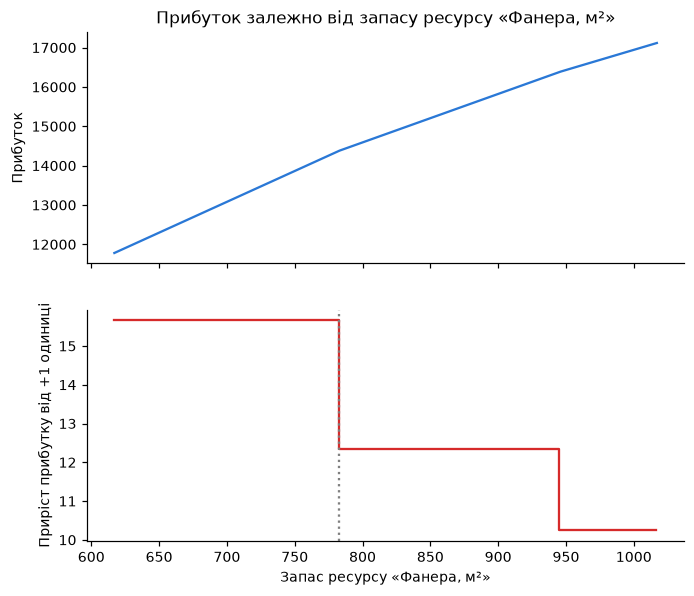

In [8]:
# ВАШ КОД
deltas = np.arange(0, 401)                     # на скільки збільшуємо запас
profits = []
for d in deltas:
    b_d = b.copy()
    b_d[k] += d
    profits.append(solve_lp(b_d)[0])
profits = np.array(profits)
slopes = np.diff(profits)                      # приріст прибутку від +1 одиниці запасу

# ділянки з постійним нахилом (тіньова ціна)
plateaus = []
for d, s in zip(deltas[:-1], slopes):
    if not plateaus or abs(s - plateaus[-1][1]) > 1e-3:   # допуск на чисельний шум розв'язувача
        plateaus.append((int(d), round(float(s), 4)))
limit = plateaus[1][0]                         # перша точка зламу
print('ділянки (з якого збільшення, нахил):', plateaus)
print('тіньова ціна %.4f діє до збільшення на %d (запас %d)' % (plateaus[0][1], limit, b[k] + limit))

fig, ax = plt.subplots(2, 1, sharex=True, figsize=(7, 6))
ax[0].plot(b[k] + deltas, profits, color='#2a78d6')
ax[0].set_ylabel('Прибуток')
ax[0].set_title('Прибуток залежно від запасу ресурсу «%s»' % ресурси[k])
ax[1].step(b[k] + deltas[:-1], slopes, where='post', color='#d62a2a')
ax[1].axvline(b[k] + limit, color='gray', ls=':')
ax[1].set_ylabel('Приріст прибутку від +1 одиниці')
ax[1].set_xlabel('Запас ресурсу «%s»' % ресурси[k])
plt.show()


**Відповідь 5.2:** Тіньова ціна 15,67 діє, поки запас фанери зростає від 617 до 783, тобто на **166** одиниць. Далі нахил падає до 12,33, а з 945 (збільшення на 328) до 10,25. Знайдена межа 166 збігається з «допустимим збільшенням» для фанери зі звіту Excel (166). Після неї змінюється склад оптимального плану, тому дорожчою одиницею ресурс уже не є.


---
# Етап 6. Рішення про закупівлю

Постачальник пропонує вам додатковий обсяг ресурсу — див. блок «ПРОПОЗИЦІЯ
ПОСТАЧАЛЬНИКА» у ваших даних.

### Завдання 6.1
Дайте відповідь директорові на три питання, спираючись на числа, а не на здоровий глузд:

1. **Брати чи не брати?** Порівняйте ціну пропозиції з тіньовою ціною.
2. **Скільки саме брати?** Постачальник пропонує більше, ніж вам потрібно.
3. **Скільки на цьому заробимо?** Порахуйте виграш і перевірте його прямим
   розв'язанням задачі з новим запасом.

ресурс: Фанера, м² | ціна 9.3 | обсяг до 332 | тіньова ціна 15.6667
купуємо   0: прибуток 11781.33 | приріст 0.00 | витрати 0.00 | чистий виграш 0.00
купуємо 166: прибуток 14382.00 | приріст 2600.67 | витрати 1543.80 | чистий виграш 1056.87
купуємо 332: прибуток 16421.00 | приріст 4639.67 | витрати 3087.60 | чистий виграш 1552.07
найкращий обсяг у межах пропозиції: 332


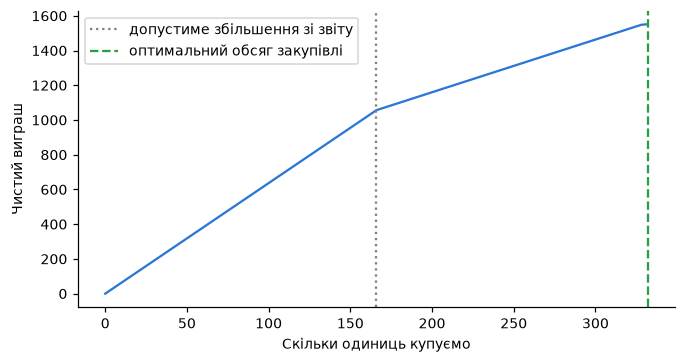

In [9]:
# ВАШ КОД
res_idx = V['ресурс_пропозиції']
price = V['ціна_пропозиції']
volume = V['обсяг_пропозиції']
print('ресурс: %s | ціна %.1f | обсяг до %d | тіньова ціна %.4f' % (
    ресурси[res_idx], price, volume, REPORT_SHADOW[res_idx]))

# чистий виграш = приріст прибутку (пряме розв'язання) - витрати на закупівлю
buy = np.arange(0, volume + 1)
net = []
for q in buy:
    b_q = b.copy()
    b_q[res_idx] += q
    net.append(solve_lp(b_q)[0] - прибуток - price * q)
net = np.array(net)
best = int(buy[np.argmax(net)])

for q in sorted({0, limit, best, volume}):
    b_q = b.copy()
    b_q[res_idx] += q
    p_q = solve_lp(b_q)[0]
    print('купуємо %3d: прибуток %.2f | приріст %.2f | витрати %.2f | чистий виграш %.2f' % (
        q, p_q, p_q - прибуток, price * q, p_q - прибуток - price * q))
print('найкращий обсяг у межах пропозиції:', best)

plt.figure(figsize=(7, 3.5))
plt.plot(buy, net, color='#2a78d6')
plt.axvline(limit, color='gray', ls=':', label='допустиме збільшення зі звіту')
plt.axvline(best, color='#2a9d4a', ls='--', label='оптимальний обсяг закупівлі')
plt.xlabel('Скільки одиниць купуємо')
plt.ylabel('Чистий виграш')
plt.legend()
plt.show()


**Відповідь 6.1:**

* Брати чи ні і чому: **Так.** Ціна пропозиції 9,3 за одиницю фанери менша за її тіньову ціну 15,67 (для перших 166 одиниць). Далі гранична цінність фанери 12,33 (166–328) і 10,25 (з 328), тобто на всьому обсязі пропозиції вона лишається вищою за 9,3.
* Скільки одиниць має сенс купити і чому не більше: **усі 332.** Допустиме збільшення 166 це межа сталості тіньової ціни, а не межа вигідності: після неї одиниця фанери приносить менше, але все ще більше за 9,3. Чистий виграш зростає до кінця пропозиції (при покупці лише 166 він лише 1 056,87). Більше 332 купити неможливо: це весь обсяг пропозиції.
* Очікуваний виграш: приріст прибутку 4 639,67 мінус витрати 332 × 9,3 = 3 087,60, тобто **1 552,07**.
* Перевірка прямим розв'язанням дала: при запасі фанери 617 + 332 = 949 оптимальний прибуток 16 421,00; 16 421,00 − 11 781,33 − 3 087,60 = **1 552,07**, що збігається з очікуваним виграшем.


---
# Етап 7. Перевірка розв'язку

### Завдання 7.1
Порахуйте дві величини:

* скільки виробів мають **ненульовий** випуск;
* скільки обмежень **зв'язні** (ресурс витрачено повністю).

Порівняйте.

In [10]:
# ВАШ КОД
slack = b - A @ план                            # залишок кожного ресурсу
ненульових = int(np.sum(план > 1e-7))
звязних = int(np.sum(np.abs(slack) < 1e-7))


In [11]:
assert ненульових is not None and звязних is not None, 'спершу порахуйте'
print('ненульових змінних: %s | зв’язних обмежень: %s' % (ненульових, звязних))
assert ненульових == звязних, ('числа не збіглися — це сигнал. Перевірте розв’язок '
                               'і поясніть причину в клітинці нижче')
print('Етап 7 пройдено')

ненульових змінних: 2 | зв’язних обмежень: 2
Етап 7 пройдено


**Відповідь 7.1:** Числа збіглися: ненульових змінних 2 і зв’язних обмежень 2 (фанера і верстат). Це типова вершина без виродження: у ній стільки ненульових змінних, скільки обмежень виконано як рівності.

Якби ненульових було менше за зв’язних, розв’язок був би **виродженим**: кілька обмежень проходять через одну вершину, а тіньові ціни й діапазони можуть бути неоднозначними (різні програми дали б різні звіти). Якби ненульових було більше за зв’язних, це сигнал помилки в моделі або розв’язку.


---
# Етап 8. Цілочисельність

Ваш оптимальний план містить дробові числа. Виготовити 63,3 виробу неможливо.

### Завдання 8.1
Порівняйте три варіанти:

1. розв'язок без умови цілочисельності (уже маєте);
2. **округлений** план — округліть кожне значення до цілого й перевірте, чи він
   узагалі допустимий і скільки прибутку дає;
3. справжній **цілочисельний** оптимум — розв'яжіть задачу з умовою, що всі змінні цілі
   (`cat='Integer'` у PuLP або `integrality=1` у `linprog`).

In [12]:
# ВАШ КОД
plan_round = np.round(план)                     # просто округляємо кожне значення
plan_ceil = np.ceil(план - 1e-9) + 0.0          # для порівняння: округлення вгору
profit_int, plan_int, _ = solve_lp(b, integer=True)

def describe(name, x):
    used = A @ x
    ok = bool(np.all(used <= b + 1e-9))
    over = [ресурси[i] for i in range(len(b)) if used[i] > b[i] + 1e-9]
    print('%-26s план %-28s прибуток %9.2f допустимий: %s %s' % (
        name, np.round(x, 2).tolist(), c @ x, ok, ('(перевищено: %s)' % ', '.join(over)) if over else ''))

describe('без цілочисельності', план)
describe('округлений', plan_round)
describe('округлення вгору', plan_ceil)
describe('цілочисельний оптимум', plan_int)
print()
print('фанера: округлений %.0f з %d | вгору %.0f з %d' % ((A @ plan_round)[1], b[1], (A @ plan_ceil)[1], b[1]))


без цілочисельності        план [72.44, 133.22, 0.0, 0.0]    прибуток  11781.33 допустимий: True 
округлений                 план [72.0, 133.0, 0.0, 0.0]      прибуток  11740.00 допустимий: True 
округлення вгору           план [73.0, 134.0, 0.0, 0.0]      прибуток  11859.00 допустимий: False (перевищено: Фанера, м², Верстат, год)
цілочисельний оптимум      план [73.0, 131.0, 0.0, 1.0]      прибуток  11743.00 допустимий: True 

фанера: округлений 615 з 617 | вгору 621 з 617


**Відповідь 8.1:**

| Варіант | План | Прибуток | Допустимий? |
|---|---|---|---|
| без умови цілочисельності | (72,44; 133,22; 0; 0) | 11 781,33 | так |
| округлений | (72; 133; 0; 0) | 11 740,00 | так (фанера 615 з 617, верстат 421 з 423) |
| цілочисельний оптимум | (73; 131; 0; 1) | 11 743,00 | так |

**Висновок:** Просто округлювати не можна. Тут округлений план вийшов допустимим, але він гірший за справжній цілочисельний оптимум (11 740 проти 11 743), а оптимальний план має зовсім інший склад (з’являється Лава). Округлення вгору (73; 134) недопустиме: фанери потрібно 621 при запасі 617, а верстата більше за запас. Тому для цілих планів треба розв’язувати задачу з умовою цілочисельності, а не округлювати, а допустимість округленого плану перевіряти завжди.


---
# ЧАСТИНА 2. Транспортна задача

Друга частина виконується самостійно. Тут ви застосуєте ту саму методику до задачі
іншого класу — і побачите, що вона поводиться інакше.

# Етап 9. Ваші дані

### Завдання 9.1
Сформуйте власні дані:

* **три міста-постачальники** — за першими трьома літерами вашого **прізвища**;
* **чотири міста-споживачі** — за першими чотирма літерами вашого **імені**;
* **матриця відстаней 3 × 4** — реальні відстані автошляхами за Google Maps, у кілометрах;
* **запаси і попит** — невеликі цілі числа, підберіть так, щоб **сумарний запас
  дорівнював сумарному попиту**.

> Якщо на якусь літеру міста немає — беріть наступну літеру прізвища чи імені.
> Якщо сумарний запас не дорівнює попиту, задача з обмеженнями-рівностями
> **не матиме розв'язку взагалі**. Це не помилка Python — це властивість моделі.

In [ ]:
# ВАШ КОД — впишіть свої дані
# Прізвище «Яцишин»: Я, Ц, И -> на «И» міста немає, беремо наступну літеру «Ш».
# Ім'я «Роман»: Р, О, М, А.
постачальники = ['Яремче', 'Цумань', 'Шостка']
споживачі     = ['Рівне', 'Одеса', 'Миколаїв', 'Апостолове']
# відстані ОРІЄНТОВНІ (пряма відстань x 1,3, округлено до 5 км)

D = np.array([[350, 665, 755, 890],
              [110, 845, 870, 930],
              [680, 820, 720, 610]])      # матриця відстаней 3 x 4, км
запас = [35, 25, 30]                      # 3 числа
попит = [20, 28, 24, 18]                  # 4 числа

assert len(постачальники) == 3 and len(споживачі) == 4, 'потрібно 3 постачальники і 4 споживачі'
assert D.shape == (3, 4), 'матриця відстаней має бути 3 x 4'
assert sum(запас) == sum(попит), 'сумарний запас має дорівнювати сумарному попиту'
pd.DataFrame(D, index=постачальники, columns=споживачі)


,Рівне,Одеса,Миколаїв,Апостолове
Яремче,350,665,755,890
Цумань,110,845,870,930
Шостка,680,820,720,610


---
# Етап 10. Розв'язання транспортної задачі

### Завдання 10.1
Розв'яжіть задачу **двічі різними засобами**: наприклад `pulp` і
`scipy.optimize.linprog(method='highs')`. Обмеження — рівності.

Для кожного розв'язку виведіть: оптимальний план перевезень, сумарну вартість
і **тіньові ціни всіх обмежень**.

In [14]:
# ВАШ КОД — розв'язок 1 (PuLP, CBC)
m = pulp.LpProblem('transport', pulp.LpMinimize)
x = [[pulp.LpVariable('x_%d_%d' % (i, j), 0) for j in range(4)] for i in range(3)]
m += pulp.lpSum(D[i][j] * x[i][j] for i in range(3) for j in range(4))
for i in range(3):
    m.addConstraint(pulp.lpSum(x[i]) == запас[i], name='sup_%d' % i)
for j in range(4):
    m.addConstraint(pulp.lpSum(x[i][j] for i in range(3)) == попит[j], name='dem_%d' % j)
m.solve(pulp.PULP_CBC_CMD(msg=0))

names = ['sup_%d' % i for i in range(3)] + ['dem_%d' % j for j in range(4)]
plan_pl = np.array([[x[i][j].value() for j in range(4)] for i in range(3)])
cost_pl = pulp.value(m.objective)
duals_pl = np.array([m.constraints[n].pi for n in names])

print('PuLP · статус:', pulp.LpStatus[m.status], '· сумарна вартість:', cost_pl)
print(pd.DataFrame(plan_pl, index=постачальники, columns=споживачі).to_string())
print('тіньові ціни:', pd.Series(duals_pl, index=постачальники + споживачі).round(2).to_dict())


PuLP · статус: Optimal · сумарна вартість: 50075.0
        Рівне  Одеса  Миколаїв  Апостолове
Яремче    0.0   28.0       7.0         0.0
Цумань   20.0    0.0       5.0         0.0
Шостка    0.0    0.0      12.0        18.0
тіньові ціни: {'Яремче': 645.0, 'Цумань': 760.0, 'Шостка': 610.0, 'Рівне': -650.0, 'Одеса': 20.0, 'Миколаїв': 110.0, 'Апостолове': 0.0}


In [15]:
# ВАШ КОД — розв'язок 2 (scipy.optimize.linprog, HiGHS)
A_eq = np.zeros((7, 12))
for i in range(3):
    A_eq[i, i * 4:(i + 1) * 4] = 1       # рядок i: сума відправлень постачальника i
for j in range(4):
    A_eq[3 + j, j::4] = 1                # стовпець j: сума отриманого споживачем j
b_eq = np.array(list(запас) + list(попит), float)

res_t = linprog(np.array(D, float).ravel(), A_eq=A_eq, b_eq=b_eq, bounds=(0, None), method='highs')
plan_hi = res_t.x.reshape(3, 4)
cost_hi = res_t.fun
duals_hi = res_t.eqlin.marginals

print('linprog · сумарна вартість:', cost_hi)
print(pd.DataFrame(plan_hi, index=постачальники, columns=споживачі).to_string())
print('тіньові ціни:', pd.Series(duals_hi, index=постачальники + споживачі).round(2).to_dict())


linprog · сумарна вартість: 50075.0
        Рівне  Одеса  Миколаїв  Апостолове
Яремче    0.0   28.0       7.0         0.0
Цумань   20.0    0.0       5.0         0.0
Шостка    0.0    0.0      12.0        18.0
тіньові ціни: {'Яремче': -0.0, 'Цумань': 115.0, 'Шостка': -35.0, 'Рівне': -5.0, 'Одеса': 665.0, 'Миколаїв': 755.0, 'Апостолове': 645.0}


### Завдання 10.2 — головне питання цієї частини
Порівняйте два набори тіньових цін.

**Сумарна вартість у двох розв'язувачів однакова. А тіньові ціни?**

Якщо вони різні — це не помилка. Знайдіть закономірність: подивіться на різницю
між відповідними значеннями окремо для постачальників і окремо для споживачів.

In [16]:
# ВАШ КОД — порівняння
print('вартість: PuLP %.2f | linprog %.2f | однакова: %s' % (cost_pl, cost_hi, bool(np.isclose(cost_pl, cost_hi))))
print('плани перевезень однакові:', bool(np.allclose(plan_pl, plan_hi, atol=1e-6)))
print('тіньові ціни однакові:', bool(np.allclose(duals_pl, duals_hi)))

diff = duals_hi - duals_pl                     # linprog - PuLP
print()
print(pd.DataFrame({'PuLP': duals_pl, 'linprog': duals_hi, 'різниця': diff},
                   index=постачальники + споживачі).round(2).to_string())
print('різниця для постачальників:', set(np.round(diff[:3], 6)))
print('різниця для споживачів:    ', set(np.round(diff[3:], 6)))

# що в обох розв'язувачах однакове: сума u_i + v_j для кожної пари (постачальник, споживач)
pair_pl = duals_pl[:3, None] + duals_pl[3:][None, :]
pair_hi = duals_hi[:3, None] + duals_hi[3:][None, :]
print('суми u_i + v_j однакові в обох розв’язувачах:', bool(np.allclose(pair_pl, pair_hi)))


вартість: PuLP 50075.00 | linprog 50075.00 | однакова: True
плани перевезень однакові: True
тіньові ціни однакові: False

             PuLP  linprog  різниця
Яремче      645.0     -0.0   -645.0
Цумань      760.0    115.0   -645.0
Шостка      610.0    -35.0   -645.0
Рівне      -650.0     -5.0    645.0
Одеса        20.0    665.0    645.0
Миколаїв    110.0    755.0    645.0
Апостолове    0.0    645.0    645.0
різниця для постачальників: {np.float64(-645.0)}
різниця для споживачів:     {np.float64(645.0)}
суми u_i + v_j однакові в обох розв’язувачах: True


**Відповідь 10.2:**

* Вартість у двох розв'язувачів: однакова, **50 075** (км·од.), плани перевезень теж однакові.
* Тіньові ціни збіглися чи ні: **не збіглися** (PuLP: 645; 760; 610; −650; 20; 110; 0, linprog: 0; 115; −35; −5; 665; 755; 645).
* Яку закономірність ви побачили в різниці: різниця однакова для всіх постачальників (−645) і така сама за модулем з протилежним знаком для всіх споживачів (+645). Тобто один розв'язувач відрізняється від іншого додаванням сталої k до всіх u постачальників і відніманням k від усіх v споживачів. Сума u + v для кожної пари в обох розв'язувачах однакова. Конкретне число k залежить від розв'язувача та його версії, а закономірність ні.
* Що це означає для того, хто збирається ухвалювати рішення за цим звітом: Обидві відповіді правильні, обидві є допустимими розв'язками двоїстої задачі. У збалансованій транспортній задачі тіньові ціни визначені лише з точністю до сталої (запас і попит пов'язані балансом), тому абсолютне значення тіньової ціни окремого обмеження не має змісту і на ньому не можна будувати рішення. Змістовними є лише різниці між ними (наприклад, наскільки дорожче постачати в один пункт, ніж в інший).


---
# Етап 11. Перевірка розв'язку — і чому вона тут не працює

### Завдання 11.1
Порахуйте для транспортної задачі те саме, що на етапі 7:

* кількість **ненульових перевезень**;
* кількість **зв'язних обмежень**.

Порівняйте з числом `3 + 4 = 7` — кількістю обмежень у задачі.

In [17]:
# ВАШ КОД
nonzero_t = int(np.sum(plan_hi > 1e-7))
residual = A_eq @ res_t.x - b_eq
binding_t = int(np.sum(np.abs(residual) < 1e-7))
print('ненульових перевезень: %d | зв’язних обмежень: %d | усього обмежень: %d' % (nonzero_t, binding_t, 3 + 4))
print('різниця між зв’язними обмеженнями та ненульовими перевезеннями:', binding_t - nonzero_t)
print('ранг матриці обмежень:', np.linalg.matrix_rank(A_eq))


ненульових перевезень: 6 | зв’язних обмежень: 7 | усього обмежень: 7
різниця між зв’язними обмеженнями та ненульовими перевезеннями: 1
ранг матриці обмежень: 6


**Відповідь 11.1:**

* Ненульових перевезень: **6**
* Зв'язних обмежень: **7** (усі)
* Чому в транспортній задачі зв'язними виявляються **всі** обмеження: усі 7 обмежень задані рівностями, тому виконуються як рівності завжди: увесь запас вивезено, увесь попит задоволено.
* На скільки ненульових перевезень менше і чому саме на стільки: на **1** (6 проти 7). Сума запасів дорівнює сумі попиту, тому одне з 7 рівнянь випливає з решти шести (ранг матриці обмежень 3 + 4 − 1 = 6). У базисі 6 змінних, тож ненульових перевезень не більше шести (рівно шість у невиродженому випадку).


### Завдання 11.2 — візуалізація
Побудуйте дві теплові карти поруч: матрицю відстаней і матрицю оптимальних перевезень.
Підпишіть осі та значення в комірках.

*За бажанням (не оцінюється): граф маршрутів через `networkx`, де товщина ребра
пропорційна обсягу перевезення.*

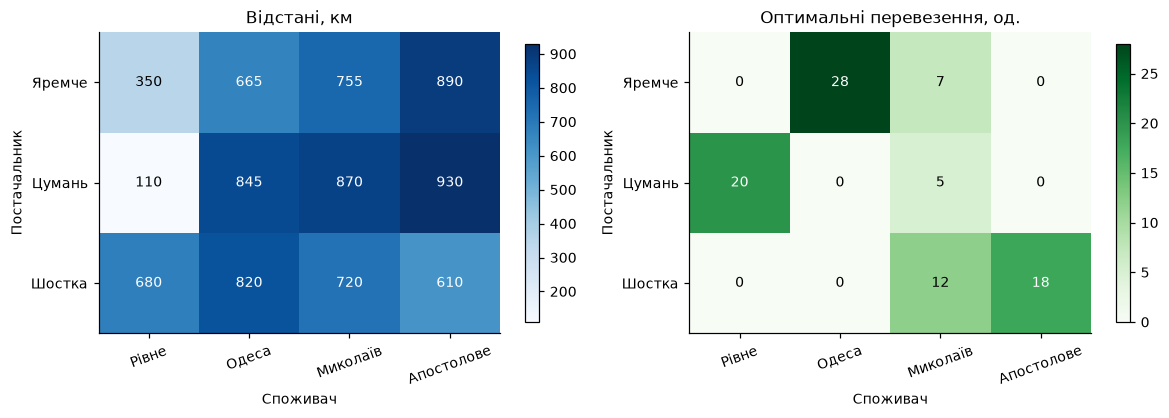

In [18]:
# ВАШ КОД
fig, ax = plt.subplots(1, 2, figsize=(11, 3.8))
for a, mat, title, cmap in [(ax[0], np.array(D, float), 'Відстані, км', 'Blues'),
                            (ax[1], plan_hi, 'Оптимальні перевезення, од.', 'Greens')]:
    im = a.imshow(mat, cmap=cmap)
    a.set_xticks(range(4))
    a.set_xticklabels(споживачі, rotation=20)
    a.set_yticks(range(3))
    a.set_yticklabels(постачальники)
    a.set_xlabel('Споживач')
    a.set_ylabel('Постачальник')
    a.set_title(title)
    for i in range(3):
        for j in range(4):
            val = mat[i, j]
            a.text(j, i, '%g' % round(val, 2), ha='center', va='center',
                   color='white' if im.norm(val) > 0.5 else 'black')
    fig.colorbar(im, ax=a, shrink=0.8)
plt.tight_layout()
plt.show()


**Висновок:** На правій карті ненульових клітинок лише 6 з 12, і вони тяжіють до «світлих» (коротких) клітинок лівої: Рівне повністю обслуговує Цумань (110 км), Апостолове — Шостка (610 км).


---
# Етап 12. Декларація про використання інструментів штучного інтелекту

Користуватися мовними моделями **дозволено**. Обов'язковою є прозорість.
Порушенням є не використання інструмента, а нездатність пояснити власний код
і власні числа на захисті.

Для кожного етапу оберіть одне: `'ні'`, `'синтаксис'`, `'код, перевірено'`,
`'текст, перероблено'`, `'текст, як є'`.

In [22]:
ІНСТРУМЕНТИ_ШІ = 'Clode'     # напр. 'ChatGPT' або 'не використовував'

ДЕКЛАРАЦІЯ = {
    'етап 1, формалізація моделі':          'код, перевірено',
    'етап 2, побудова моделі в Excel':      'код, перевірено',
    'етап 3, код на Python':                'код, перевірено',
    'етапи 4–5, читання та перевірка звіту': 'код, перевірено',
    'етап 6, рішення про закупівлю':        'код, перевірено',
    'етапи 7–8, перевірка та цілочисельність': 'код, перевірено',
    'етапи 9–11, транспортна задача':       'код, перевірено',
}

# Що саме ви перевірили за згенерованим кодом чи текстом — конкретно.
ЩО_ПЕРЕВІРЕНО = 'Загальне бачення щодо розв’язку задачі, перевірка правильності формул, перевірка результатів на відповідність очікуваним, порівняння з Excel та іншими методами розв’язання.'

# True означає: я можу пояснити кожен рядок свого коду, відтворити будь-яке число
# цієї роботи та внести зміни в модель на вимогу під час захисту.
ПІДТВЕРДЖУЮ = True

In [23]:
# --- перевірка повноти декларації: клітинку не редагувати --------------------
ДОЗВОЛЕНІ = {'ні', 'синтаксис', 'код, перевірено', 'текст, перероблено', 'текст, як є'}
assert ІНСТРУМЕНТИ_ШІ.strip(), 'Вкажіть інструменти або напишіть «не використовував»'
порожні = [k for k, v in ДЕКЛАРАЦІЯ.items() if not str(v).strip()]
assert not порожні, 'Не заповнено: %s' % '; '.join(порожні)
чужі = {v for v in ДЕКЛАРАЦІЯ.values() if v not in ДОЗВОЛЕНІ}
assert not чужі, 'Недопустимі значення: %s' % ', '.join(sorted(чужі))
assert len(ЩО_ПЕРЕВІРЕНО.strip()) >= 120, ('Опишіть конкретніше (зараз %d символів, '
                                           'потрібно щонайменше 120)' % len(ЩО_ПЕРЕВІРЕНО.strip()))
assert ПІДТВЕРДЖУЮ is True, 'Підтвердьте, що можете пояснити власний код на захисті'
print('ДЕКЛАРАЦІЯ ПРО ВИКОРИСТАННЯ ІНСТРУМЕНТІВ ШІ')
print('=' * 78)
print('%-42s %s' % ('автор:', ПІБ))
print('%-42s %s' % ('інструменти:', ІНСТРУМЕНТИ_ШІ))
print('-' * 78)
for k, v in ДЕКЛАРАЦІЯ.items():
    print('%-42s %s' % (k + ':', v))
print('-' * 78)
print(ЩО_ПЕРЕВІРЕНО)

ДЕКЛАРАЦІЯ ПРО ВИКОРИСТАННЯ ІНСТРУМЕНТІВ ШІ
автор:                                     Яцишин Роман
інструменти:                               Clode
------------------------------------------------------------------------------
етап 1, формалізація моделі:               код, перевірено
етап 2, побудова моделі в Excel:           код, перевірено
етап 3, код на Python:                     код, перевірено
етапи 4–5, читання та перевірка звіту:     код, перевірено
етап 6, рішення про закупівлю:             код, перевірено
етапи 7–8, перевірка та цілочисельність:   код, перевірено
етапи 9–11, транспортна задача:            код, перевірено
------------------------------------------------------------------------------
Загальне бачення щодо розв’язку задачі, перевірка правильності формул, перевірка результатів на відповідність очікуваним, порівняння з Excel та іншими методами розв’язання.


---
# Крок 13. Фінальна самоперевірка

In [24]:
перевірки = {
    'ПІБ і варіант заповнено':            bool(ПІБ) and 1 <= ВАРІАНТ <= 30,
    'Excel і Python дали однаковий план': abs(прибуток - EXCEL_ПРИБУТОК) < 0.5,
    'перевірку «ненульові = зв’язні» зроблено': ненульових == звязних,
    'дані транспортної задачі введено':   len(постачальники) == 3 and len(споживачі) == 4,
    'баланс запасів і попиту':            sum(запас) == sum(попит),
    'декларацію заповнено':               bool(ІНСТРУМЕНТИ_ШІ.strip()) and ПІДТВЕРДЖУЮ is True,
}
for k, v in перевірки.items():
    print(('OK   ' if v else 'НЕ ОК') + '  ' + k)
if all(перевірки.values()):
    print('\nТехнічна частина виконана.')
    print('Переконайтеся, що заповнені ВСІ клітинки з відповідями,')
    print('і виконайте Kernel → Restart & Run All перед здачею.')

OK     ПІБ і варіант заповнено
OK     Excel і Python дали однаковий план
OK     перевірку «ненульові = зв’язні» зроблено
OK     дані транспортної задачі введено
OK     баланс запасів і попиту
OK     декларацію заповнено

Технічна частина виконана.
Переконайтеся, що заповнені ВСІ клітинки з відповідями,
і виконайте Kernel → Restart & Run All перед здачею.
